# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: Ngo Dong At

I have used the following AI tools: Claude, ChatGPT, NotebookLM

I understand that my submission needs to be my own work: NDA

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [19]:
# # change directory to Google Drive for Google Colab
# try:
#     from google.colab import drive
#     import os

#     drive.mount('/content/drive')
#     os.chdir('/content/drive/My Drive/Colab Notebooks/')
#     print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
# except ImportError:
#     pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [20]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [21]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [22]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('west')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [23]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [24]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: east
step 1 - action: south
step 2 - action: south
step 3 - action: south
step 4 - action: west
step 5 - action: south
step 6 - action: east
step 7 - action: east
step 8 - action: east
step 9 - action: north
step 10 - action: north
step 11 - action: west
step 12 - action: north
step 13 - action: south
step 14 - action: suck
step 15 - action: south
step 16 - action: suck
step 17 - action: east
step 18 - action: suck
step 19 - action: north


3

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [25]:
import numpy as np

def create_room(n, p=0.2):
    return np.random.rand(n, n) < p


def environment(agent_function, n=5, p=0.2, max_steps=10000, verbose=False):

    room = create_room(n, p)                            # True = dirty
    pos = [np.random.randint(n), np.random.randint(n)]  # [row, col], agent starts on a random square

    for step in range(max_steps):
        # stop as soon as every square is clean -- this IS the performance measure
        if not room.any():
            return step

        r, c = pos
        bumpers = {
            "north": r == 0,
            "south": r == n - 1,
            "west":  c == 0,
            "east":  c == n - 1,
        }
        dirty = bool(room[r, c])

        action = agent_function(bumpers, dirty)

        if verbose:
            print(f"step {step:4d}: pos=({r},{c}) dirty={dirty} bumpers={bumpers} -> action=\'{action}\'")

        if action == "suck":
            room[r, c] = False
        elif action == "north" and not bumpers["north"]:
            pos[0] -= 1
        elif action == "south" and not bumpers["south"]:
            pos[0] += 1
        elif action == "west" and not bumpers["west"]:
            pos[1] -= 1
        elif action == "east" and not bumpers["east"]:
            pos[1] += 1
        # if the action would bump into a wall (or is invalid), the agent just stays put
        # -- this still costs one energy unit, exactly as a real bump would.

    # ran out of energy before the room was fully clean
    return max_steps

Show that your environment works with the simple randomized agent from above.

In [26]:
np.random.seed(1)
cost = environment(simple_randomized_agent, n=5, p=0.2, max_steps=200, verbose=True)
print(f"\nRandomized agent cleaned the 5x5 room in {cost} actions.")

step    0: pos=(4,1) dirty=False bumpers={'north': False, 'south': True, 'west': False, 'east': False} -> action='north'
step    1: pos=(3,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='north'
step    2: pos=(2,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='south'
step    3: pos=(3,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='west'
step    4: pos=(3,0) dirty=False bumpers={'north': False, 'south': False, 'west': True, 'east': False} -> action='east'
step    5: pos=(3,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='north'
step    6: pos=(2,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='south'
step    7: pos=(3,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='east'
step    8: pos=(3,2) dirty=Fa

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [27]:
def simple_reflex_agent(bumpers, dirty):

    if dirty:
        return "suck"

    free_directions = [d for d in ("north", "east", "west", "south") if not bumpers[d]]
    return np.random.choice(free_directions)


Show how the agent works with your environment.

In [28]:
np.random.seed(1)
cost = environment(simple_reflex_agent, n=5, p=0.2, max_steps=200, verbose=True)
print(f"\nSimple reflex agent cleaned the 5x5 room in {cost} actions.")

step    0: pos=(4,1) dirty=False bumpers={'north': False, 'south': True, 'west': False, 'east': False} -> action='north'
step    1: pos=(3,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='north'
step    2: pos=(2,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='east'
step    3: pos=(2,2) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='south'
step    4: pos=(3,2) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='south'
step    5: pos=(4,2) dirty=False bumpers={'north': False, 'south': True, 'west': False, 'east': False} -> action='west'
step    6: pos=(4,1) dirty=False bumpers={'north': False, 'south': True, 'west': False, 'east': False} -> action='east'
step    7: pos=(4,2) dirty=False bumpers={'north': False, 'south': True, 'west': False, 'east': False} -> action='north'
step    8: pos=(3,2) dirty=Fals

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

In [29]:
# Your short description of the state and your implementation goes here

### Agent state design

The model-based agent needs to guarantee that it visits **every** square in the room, not just
wander randomly, otherwise it could miss dirty squares forever. To do this it keeps three pieces
of state:

- `located` (`bool`): whether the agent has already found the north-west corner `(0, 0)`. Bumpers
  are 100% reliable, so the agent first walks `north` until the north bumper fires, then `west`
  until the west bumper fires. Once both have fired, the agent *knows* its exact position - this
  is the only way a memory-less percept stream (bumpers + dirt) can be turned into a coordinate.
- `path` (`list[str]`): a **boustrophedon** ("ox-plough", zig-zag) sequence of moves computed once
  from the known room size `n` (allowed by the PEAS description: *"the agent knows the size ... of
  the room"*). Going east across row 0, south once, west across row 1, south once, east across row
  2, etc. visits every one of the `n x n` squares exactly once using only `n^2 - 1` moves.
- `path_index` / `sucked_current_cell`: which move comes next, and whether the agent has already
  decided whether to suck the square it is currently standing on.

Because the traversal order does not depend on where the dirt actually is, the agent is guaranteed
to eventually visit every square - and it stops early (the environment loop exits) as soon as all
discovered dirt has been sucked up, so on average it usually finishes well before visiting all
`n^2` squares.

In [30]:
def boustrophedon_path(n):
    path = []
    for row in range(n):
        direction = "east" if row % 2 == 0 else "west"
        path += [direction] * (n - 1)
        if row < n - 1:
            path.append("south")
    return path


class ModelBasedVacuumAgent:

    def __init__(self, n):
        self.n = n
        self.located = False
        self.path = boustrophedon_path(n)
        self.path_index = 0
        self.sucked_current_cell = False

    def _should_suck(self, dirty):
        # its own method so the noisy-sensor version (Advanced task) can override it
        return dirty

    def act(self, bumpers, dirty):
        # Phase 1: find the NW corner using the (reliable) bumper sensors
        if not self.located:
            if not bumpers["north"]:
                return "north"
            if not bumpers["west"]:
                return "west"
            self.located = True

        # Phase 2: sweep the room in a fixed zig-zag order
        if not self.sucked_current_cell:
            self.sucked_current_cell = True
            if self._should_suck(dirty):
                return "suck"

        if self.path_index < len(self.path):
            move = self.path[self.path_index]
            self.path_index += 1
            self.sucked_current_cell = False
            return move

        return "suck"  # sweep finished; nothing meaningful left to do

Show how the agent works with your environment.

In [31]:
np.random.seed(1)
agent = ModelBasedVacuumAgent(n=5)
cost = environment(agent.act, n=5, p=0.2, max_steps=200, verbose=True)
print(f"\nModel-based reflex agent cleaned the 5x5 room in {cost} actions.")

step    0: pos=(4,1) dirty=False bumpers={'north': False, 'south': True, 'west': False, 'east': False} -> action='north'
step    1: pos=(3,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='north'
step    2: pos=(2,1) dirty=False bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='north'
step    3: pos=(1,1) dirty=True bumpers={'north': False, 'south': False, 'west': False, 'east': False} -> action='north'
step    4: pos=(0,1) dirty=False bumpers={'north': True, 'south': False, 'west': False, 'east': False} -> action='west'
step    5: pos=(0,0) dirty=False bumpers={'north': True, 'south': False, 'west': True, 'east': False} -> action='east'
step    6: pos=(0,1) dirty=False bumpers={'north': True, 'south': False, 'west': False, 'east': False} -> action='east'
step    7: pos=(0,2) dirty=True bumpers={'north': True, 'south': False, 'west': False, 'east': False} -> action='suck'
step    8: pos=(0,2) dirty=False bum

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [32]:
def run_experiment(agent_factory, n, n_runs=100, max_steps=None):
    if max_steps is None:
        max_steps = 20 * n * n  # generous energy budget so agents rarely run out
    costs = np.empty(n_runs)
    for i in range(n_runs):
        agent_function = agent_factory(n)
        costs[i] = environment(agent_function, n=n, max_steps=max_steps, verbose=False)
    return costs


# a fresh agent instance per run, since the model-based agent carries memory (state)
agent_factories = {
    "Randomized Agent":         lambda n: simple_randomized_agent,
    "Simple Reflex Agent":      lambda n: simple_reflex_agent,
    "Model-based Reflex Agent": lambda n: ModelBasedVacuumAgent(n).act,
}

# energy budgets tuned per size: generous for the agents that finish fast (model-based),
# capped for the naive agents at very large n so a stuck run doesn't take forever
max_steps_by_size = {5: 300, 10: 2000, 100: 50000}

sizes = [5, 10, 100]
n_runs = 100

results = {}  # (size, agent_name) -> mean cost
np.random.seed(42)
for size in sizes:
    for name, factory in agent_factories.items():
        costs = run_experiment(factory, size, n_runs=n_runs, max_steps=max_steps_by_size[size])
        results[(size, name)] = costs.mean()
        print(f"n={size:>3} | {name:<26} | avg actions over {n_runs} runs = {results[(size, name)]:.2f}")

n=  5 | Randomized Agent           | avg actions over 100 runs = 265.79
n=  5 | Simple Reflex Agent        | avg actions over 100 runs = 109.42
n=  5 | Model-based Reflex Agent   | avg actions over 100 runs = 29.23
n= 10 | Randomized Agent           | avg actions over 100 runs = 1958.50
n= 10 | Simple Reflex Agent        | avg actions over 100 runs = 943.67
n= 10 | Model-based Reflex Agent   | avg actions over 100 runs = 124.84
n=100 | Randomized Agent           | avg actions over 100 runs = 50000.00
n=100 | Simple Reflex Agent        | avg actions over 100 runs = 50000.00
n=100 | Model-based Reflex Agent   | avg actions over 100 runs = 12086.09


Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     | | | |
| 10x10   | | | |
| 100x100 | | | |

Add charts to compare the performance of the different agents.

The table below is generated automatically from the experiment above (rounded to two
decimals), followed by a chart comparing all three agents across room sizes.

,Randomized Agent,Simple Reflex Agent,Model-based Reflex Agent
Size,,,
5,265.79,109.42,29.23
10,1958.50,943.67,124.84
100,50000.00,50000.00,12086.09


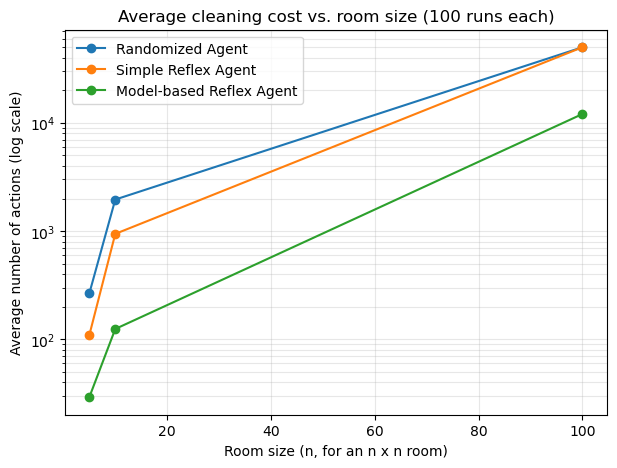

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Build a tidy results table: rows = room size, columns = agent
table = pd.DataFrame(index=sizes, columns=list(agent_factories.keys()), dtype=float)
for size in sizes:
    for name in agent_factories:
        table.loc[size, name] = round(results[(size, name)], 2)
table.index.name = "Size"
display(table)

# Chart: average actions vs. room size (log scale, since costs span orders of magnitude)
fig, ax = plt.subplots(figsize=(7, 5))
for name in agent_factories:
    ax.plot(sizes, [results[(s, name)] for s in sizes], marker="o", label=name)
ax.set_xlabel("Room size (n, for an n x n room)")
ax.set_ylabel("Average number of actions (log scale)")
ax.set_yscale("log")
ax.set_title("Average cleaning cost vs. room size (100 runs each)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

**Discussion.** The randomized agent and, to a lesser extent, the simple reflex agent both rely
on chance to stumble onto every dirty square. Their expected cost grows much faster than `n^2`
because a random walk needs far more steps than the number of squares to *cover* a large grid
(their curves rise steeply on the log scale above, and at `n = 100` many runs hit the energy cap
without ever finishing, so their reported average is really a lower bound on how bad they are).
The model-based reflex agent's cost grows smoothly and stays close to `n^2` for every size, because
its zig-zag sweep visits each square at most once and does not depend on luck at all -- the gap
between it and the other two agents widens dramatically as the room gets bigger.

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

In [34]:
# Answers goes here

**Rectangular room of unknown size.** The locate phase (walking to the NW corner) still works,
since it only relies on the two reliable bumpers. But the pre-computed zig-zag `path` needs to know
`n` in advance - for an unknown/rectangular size, the agent would instead need to discover the far
bumpers *while* sweeping (e.g., walk east until the east bumper fires to learn the row length, then
go south one row at a time until the south bumper fires to learn the number of rows), building the
path incrementally instead of computing it upfront.

**Irregular shape (e.g. a hallway connecting two rooms).** The fixed zig-zag path assumes a solid
rectangle; it would walk straight through squares that don't exist and never notice a hallway
branching off to a second room, so parts of the space would simply never be visited. A depth-first
/ wall-following ("always keep a hand on the left wall") strategy that reacts to bumpers as they
occur, rather than following a precomputed plan, generalizes much better to irregular layouts.

**Obstacles the agent doesn't know about.** An obstacle triggers a bumper exactly like an outer
wall does, so the agent's *locate* phase would stop early (thinking it has reached a corner when it
has really just bumped into furniture), corrupting its internal coordinate system - the rest of
the precomputed sweep would then be based on a wrong map and likely skip real squares or revisit
others. The agent would need to treat "bumper fired but I'm not yet where the plan expected" as a
sign to replan locally rather than trusting the fixed path blindly.

**Dirt sensor wrong 10% of the time.** Since our model-based agent's *movement* never depends on
the dirty percept (only the "should I suck here?" decision does), the zig-zag sweep still visits
every square in the same fixed number of moves - but around 10% of truly dirty squares would be
perceived as clean and skipped (never sucked), and around 10% of clean squares would trigger a
harmless, wasted `suck`. So the `n^2`-ish energy cost stays about the same, but the room ends up not
fully clean. See the Advanced task below for a fix.

**Bumper sensor wrong 10% of the time (occasionally fails to report a wall).** This is more
damaging, because the *locate* phase and the whole zig-zag path depend on bumpers being ground
truth. A missed wall reading during locating could make the agent think it reached the corner one
square too early or too late, silently shifting its whole internal coordinate frame - every
subsequent move in the sweep would then be based on a wrong position, and the agent could "walk
off" its internal map or bump into a real wall it wasn't expecting, with no way to detect that its
coordinates have drifted. Making the agent robust to this would need redundancy - e.g., confirming
a wall with more than one reading before trusting it - rather than the current single-reading
design.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [35]:
def noisy_environment(agent_function, n=5, p=0.2, sensor_noise=0.1, max_steps=2000, verbose=False):
    room = create_room(n, p)
    pos = [np.random.randint(n), np.random.randint(n)]

    for step in range(max_steps):
        r, c = pos
        bumpers = {
            "north": r == 0, "south": r == n - 1,
            "west":  c == 0, "east":  c == n - 1,
        }
        true_dirty = bool(room[r, c])
        dirty = (not true_dirty) if (np.random.rand() < sensor_noise) else true_dirty

        action = agent_function(bumpers, dirty)

        if verbose:
            print(f"step {step:4d}: pos=({r},{c}) true_dirty={true_dirty} sensed={dirty} -> action=\'{action}\'")

        if action == "suck":
            room[r, c] = False  # the actuator itself is perfectly reliable
        elif action == "north" and not bumpers["north"]:
            pos[0] -= 1
        elif action == "south" and not bumpers["south"]:
            pos[0] += 1
        elif action == "west" and not bumpers["west"]:
            pos[1] -= 1
        elif action == "east" and not bumpers["east"]:
            pos[1] += 1

    return max_steps, int(room.sum())


class RobustModelBasedVacuumAgent(ModelBasedVacuumAgent):
    def _should_suck(self, dirty):
        return True


def run_noisy_experiment(agent_factory, n, n_runs=100, sensor_noise=0.1, max_steps=None):
    if max_steps is None:
        max_steps = 3 * n * n
    dirty_left = np.empty(n_runs)
    for i in range(n_runs):
        agent_function = agent_factory(n)
        _, left = noisy_environment(agent_function, n=n, sensor_noise=sensor_noise, max_steps=max_steps)
        dirty_left[i] = left
    return dirty_left


np.random.seed(0)
n = 10
noisy_factories = {
    "Randomized Agent":                    lambda n: simple_randomized_agent,
    "Simple Reflex Agent":                  lambda n: simple_reflex_agent,
    "Model-based (naive, trusts sensor)":   lambda n: ModelBasedVacuumAgent(n).act,
    "Model-based (robust, ignores sensor)": lambda n: RobustModelBasedVacuumAgent(n).act,
}

print(f"10%-noisy dirt sensor, {n}x{n} room, energy budget = {3*n*n} actions, 100 runs:\n")
for name, factory in noisy_factories.items():
    left = run_noisy_experiment(factory, n, n_runs=100, sensor_noise=0.1)
    print(f"{name:<38} avg squares still dirty at the end = {left.mean():.2f} (out of ~{0.2*n*n:.0f} initially dirty)")

10%-noisy dirt sensor, 10x10 room, energy budget = 300 actions, 100 runs:

Randomized Agent                       avg squares still dirty at the end = 13.49 (out of ~20 initially dirty)
Simple Reflex Agent                    avg squares still dirty at the end = 7.30 (out of ~20 initially dirty)
Model-based (naive, trusts sensor)     avg squares still dirty at the end = 2.07 (out of ~20 initially dirty)
Model-based (robust, ignores sensor)   avg squares still dirty at the end = 0.00 (out of ~20 initially dirty)


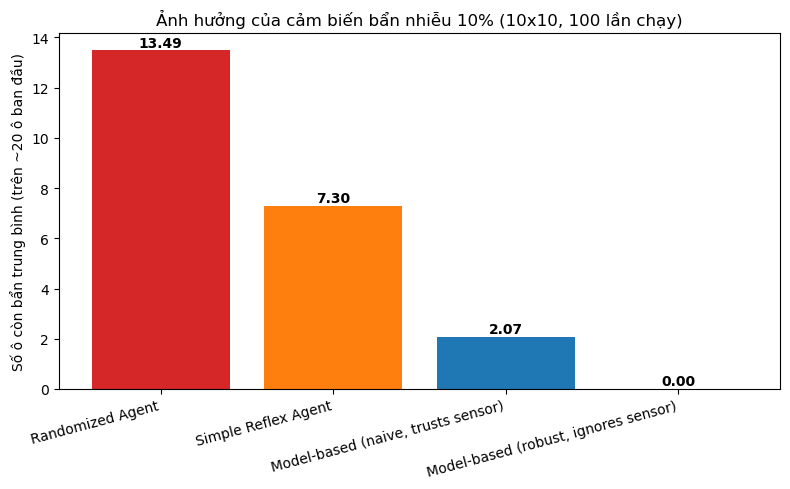

In [36]:
np.random.seed(0)
# Biểu đồ so sánh trực quan cho phần Advanced task (cảm biến bẩn nhiễu 10%)
import matplotlib.pyplot as plt

results_noisy = {}
for name, factory in noisy_factories.items():
    left = run_noisy_experiment(factory, n, n_runs=100, sensor_noise=0.1)
    results_noisy[name] = left.mean()

fig, ax = plt.subplots(figsize=(8, 5))
names = list(results_noisy.keys())
values = [results_noisy[k] for k in names]
colors = ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c"]

bars = ax.bar(names, values, color=colors)
ax.set_ylabel(f"Số ô còn bẩn trung bình (trên ~{0.2*n*n:.0f} ô ban đầu)")
ax.set_title(f"Ảnh hưởng của cảm biến bẩn nhiễu 10% ({n}x{n}, 100 lần chạy)")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=15, ha="right")

for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.15, f"{v:.2f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Discussion.** The naive model-based agent still sweeps every square in the same fixed
`n^2`-ish number of actions - but because it only sucks when the (noisy) sensor says "dirty", it
ends up leaving roughly 10% of the truly dirty squares uncleaned. The robust version ignores the
sensor for the suck decision and simply sucks every square it visits once: since the suck actuator
itself is reliable, this brings the number of squares left dirty down to (essentially) zero,
regardless of the noise level - at the cost of a fixed number of extra `suck` actions (one per
square) rather than only sucking where needed. This is a clean example of the classic
energy-vs-accuracy tradeoff: the robust agent trades a small, constant amount of extra energy for
a large, reliable gain in cleanliness.


## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [37]:
# Your ideas/code